In [ ]:
# Import os module to work with files, folders, and directory paths
import os

# Import NumPy for numerical operations and working with arrays
import numpy as np

# Import Pandas for data manipulation and analysis using DataFrames
import pandas as pd

# Import Matplotlib for creating graphs and visualizations
import matplotlib.pyplot as plt

# Import TensorFlow for building, training, and evaluating deep learning models
import tensorflow as tf

# Import Sequential to build a neural network layer by layer
# Import load_model to load a previously saved neural network model
from tensorflow.keras.models import Sequential, load_model

# Import Input to define the input shape of the neural network
# Import Dense to create fully connected neural network layers
from tensorflow.keras.layers import Input, Dense

# Import ModelCheckpoint to save the model during training
# It can save the best model based on validation loss or accuracy
from tensorflow.keras.callbacks import ModelCheckpoint

# Import train_test_split to divide the dataset into training and testing sets
from sklearn.model_selection import train_test_split

# Import StandardScaler to standardize numerical features
# It transforms features to have a mean of 0 and standard deviation of 1
from sklearn.preprocessing import StandardScaler

In [ ]:

# ============================================================
# STEP 1: GENERATE DATASET
# ============================================================

np.random.seed(42)
tf.random.set_seed(42)

n = 1000

df = pd.DataFrame({
    "Age": np.random.randint(18, 60, n),
    "Salary": np.random.randint(20000, 150000, n),
    "Experience": np.random.randint(0, 20, n)
})

df["Target"] = (
    (df["Salary"] > 70000) &
    (df["Experience"] > 5)
).astype(int)

print(df.head())

# ============================================================
# STEP 2: SPLIT DATASET
# ============================================================

X = df[["Age", "Salary", "Experience"]]
y = df["Target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# ============================================================
# STEP 3: FEATURE SCALING
# ============================================================

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


   Age  Salary  Experience  Target
0   56  146108          14       1
1   46   34382          15       0
2   32  104291          19       1
3   25  121195           0       0
4   38   23756           9       0


In [ ]:
# ============================================================
# STEP 4: BUILD NEURAL NETWORK
# ============================================================

# Create a Sequential neural network model
# Sequential means layers are connected one after another
model = Sequential([

    # INPUT LAYER
    # Input shape (3,) means the dataset contains 3 input features
    # Example: Age, Salary, Experience
    Input(shape=(3,)),

    # HIDDEN LAYER
    # Dense(5) creates 5 neurons in the hidden layer
    # Each neuron receives input from all 3 input features
    # ReLU activation converts negative values to 0
    # ReLU formula: f(x) = max(0, x)
    # Hidden layer parameters = (3 * 5) + 5 biases = 20
    Dense(
        5,
        activation="relu",
        name="Hidden_Layer"
    ),

    # OUTPUT LAYER
    # Dense(1) creates 1 output neuron
    # Sigmoid activation produces a probability between 0 and 1
    # Sigmoid formula: f(x) = 1 / (1 + exp(-x))
    # Suitable for binary classification problems
    # Example: 0 = No, 1 = Yes
    # Output layer parameters = (5 * 1) + 1 bias = 6
    Dense(
        1,
        activation="sigmoid",
        name="Output_Layer"
    )
])

# ============================================================
# COMPILE THE NEURAL NETWORK
# ============================================================

# Compile configures how the neural network will learn
model.compile(

    # OPTIMIZER
    # Adam updates weights and biases during training
    # Learning rate 0.01 controls the size of weight updates
    # Higher learning rate = larger updates, may cause instability
    # Lower learning rate = smaller updates, may require more epochs
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),

    # LOSS FUNCTION
    # Binary crossentropy measures prediction error
    # Used for binary classification with sigmoid output
    # The training process tries to minimize this loss
    loss="binary_crossentropy",

    # EVALUATION METRIC
    # Accuracy measures the proportion of correct predictions
    # Example: 90 correct predictions out of 100 = 90% accuracy
    metrics=["accuracy"]
)

# ============================================================
# DISPLAY NEURAL NETWORK ARCHITECTURE
# ============================================================

# Print model architecture and layer information
# Shows layer names, output shapes, and parameter counts
# Total trainable parameters = 20 + 6 = 26
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Hidden_Layer (Dense)            │ (None, 5)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26 (104.00 B)

 Trainable params: 26 (104.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Define the file path where the neural network model checkpoint will be saved
# .keras is the recommended native Keras model format
checkpoint_path = "neural_network_checkpoint.keras"

# Create a ModelCheckpoint callback to save the model during training
checkpoint = ModelCheckpoint(

    # Specify the filename or path where the model will be saved
    filepath=checkpoint_path,

    # Monitor validation loss to track model performance on validation data
    # Lower validation loss generally indicates better validation performance
    monitor="val_loss",

    # False = Save the model at the end of every epoch, overwriting the same file
    # True = Save the model only when the monitored metric improves
    save_best_only=False,

    # False = Save the complete model architecture, weights, and optimizer state
    # True = Save only the model weights (requires a .weights.h5 filepath)
    save_weights_only=False,

    # 1 = Display a message whenever the checkpoint is saved
    # 0 = Do not display checkpoint-saving messages
    verbose=1
)

In [ ]:

# ============================================================
# STEP 6: TRAIN FIRST 100 EPOCHS
# ============================================================

print("\nTRAINING FROM EPOCH 1 TO 100")

history1 = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[checkpoint],
    verbose=1
)

print("\nFirst 100 Epochs Completed")
print("Checkpoint Saved:", checkpoint_path)

# ============================================================
# STEP 7: CHECK MODEL WEIGHTS
# ============================================================

print("\nWeights after 100 epochs:")

for layer in model.layers:
    weights, biases = layer.get_weights()
    print(layer.name)
    print("Weights:", weights)
    print("Biases:", biases)

# ============================================================
# STEP 8: LOAD MODEL FROM CHECKPOINT
# ============================================================

print("\nLoading Saved Checkpoint...")

resumed_model = load_model(checkpoint_path)

resumed_model.summary()

print("\nCheckpoint Loaded Successfully")

# ============================================================
# STEP 9: VERIFY OPTIMIZER ITERATIONS
# ============================================================

print(
    "Optimizer Steps Completed:",
    int(resumed_model.optimizer.iterations.numpy())
)

# ============================================================
# STEP 10: CONTINUE TRAINING
# EPOCH 101 TO EPOCH 200
# ============================================================

print("\nRESUMING TRAINING FROM EPOCH 101")

history2 = resumed_model.fit(
    X_train,
    y_train,
    initial_epoch=100,
    epochs=200,
    batch_size=32,
    validation_split=0.2,
    callbacks=[checkpoint],
    verbose=1
)

print("\nTraining Completed: 200 Total Epochs")


TRAINING FROM EPOCH 1 TO 100
Epoch 1/100
 1/20 ━━━━━━━━━━━━━━━━━━━━ 16s 861ms/step - accuracy: 0.2812 - loss: 0.7920
Epoch 1: saving model to neural_network_checkpoint.keras

Epoch 1: finished saving model to neural_network_checkpoint.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.4156 - loss: 0.7148 - val_accuracy: 0.5000 - val_loss: 0.6476
Epoch 2/100
 1/20 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.6250 - loss: 0.5736
Epoch 2: saving model to neural_network_checkpoint.keras

Epoch 2: finished saving model to neural_network_checkpoint.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5938 - loss: 0.5755 - val_accuracy: 0.6625 - val_loss: 0.5614
Epoch 3/100
 1/20 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.6250 - loss: 0.5137
Epoch 3: saving model to neural_network_checkpoint.keras

Epoch 3: finished saving model to neural_network_checkpoint.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7391 - loss: 0.5045 - val_accuracy: 0.7250 - val_loss:

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Hidden_Layer (Dense)            │ (None, 5)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 80 (324.00 B)

 Trainable params: 26 (104.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 54 (220.00 B)


Checkpoint Loaded Successfully
Optimizer Steps Completed: 2000

RESUMING TRAINING FROM EPOCH 101
Epoch 101/200
 1/20 ━━━━━━━━━━━━━━━━━━━━ 10s 556ms/step - accuracy: 1.0000 - loss: 0.0050
Epoch 101: saving model to neural_network_checkpoint.keras

Epoch 101: finished saving model to neural_network_checkpoint.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 1.0000 - loss: 0.0138 - val_accuracy: 1.0000 - val_loss: 0.0258
Epoch 102/200
 1/20 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 1.0000 - loss: 0.0049
Epoch 102: saving model to neural_network_checkpoint.keras

Epoch 102: finished saving model to neural_network_checkpoint.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 1.0000 - loss: 0.0137 - val_accuracy: 1.0000 - val_loss: 0.0256
Epoch 103/200
 1/20 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 1.0000 - loss: 0.0048
Epoch 103: saving model to neural_network_checkpoint.keras

Epoch 103: finished saving model to neural_network_checkpoint.keras
20/20 ━━━━━━━━━━━━━━━


Final Test Loss: 0.007701963186264038
Final Test Accuracy: 1.0


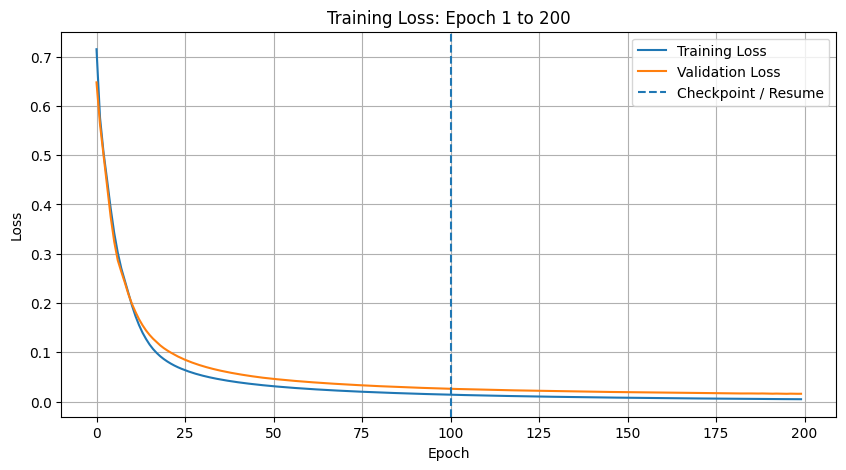

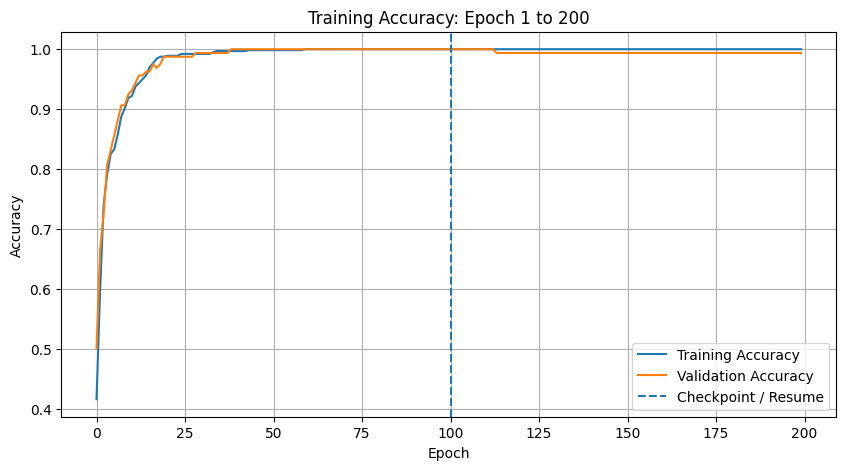

In [ ]:

# ============================================================
# STEP 11: EVALUATE FINAL MODEL
# ============================================================

loss, accuracy = resumed_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("\nFinal Test Loss:", loss)
print("Final Test Accuracy:", accuracy)

# ============================================================
# STEP 12: COMBINE TRAINING HISTORY
# ============================================================

total_loss = (
    history1.history["loss"] +
    history2.history["loss"]
)

total_val_loss = (
    history1.history["val_loss"] +
    history2.history["val_loss"]
)

total_accuracy = (
    history1.history["accuracy"] +
    history2.history["accuracy"]
)

total_val_accuracy = (
    history1.history["val_accuracy"] +
    history2.history["val_accuracy"]
)

# ============================================================
# STEP 13: PLOT LOSS FOR 200 EPOCHS
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(total_loss, label="Training Loss")
plt.plot(total_val_loss, label="Validation Loss")

plt.axvline(
    x=100,
    linestyle="--",
    label="Checkpoint / Resume"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss: Epoch 1 to 200")
plt.legend()
plt.grid(True)
plt.show()

# ============================================================
# STEP 14: PLOT ACCURACY FOR 200 EPOCHS
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(total_accuracy, label="Training Accuracy")
plt.plot(total_val_accuracy, label="Validation Accuracy")

plt.axvline(
    x=100,
    linestyle="--",
    label="Checkpoint / Resume"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training Accuracy: Epoch 1 to 200")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:

# ============================================================
# STEP 15: SAVE FINAL MODEL
# ============================================================

resumed_model.save("final_model_200_epochs.keras")

print("\nFinal Model Saved Successfully")

# ============================================================
# STEP 16: FINAL OPTIMIZER STEPS
# ============================================================

print(
    "Total Optimizer Steps:",
    int(resumed_model.optimizer.iterations.numpy())
)



Final Model Saved Successfully
Total Optimizer Steps: 4000


In [ ]:
import seaborn as sns
df=sns.load_dataset("titanic")
df=df[df.describe().columns]
df.fillna(20,inplace=True)
x=df.drop('survived',axis=1)
y=df['survived']